In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

from sklearn.metrics import  confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

df = pd.read_csv('../01 - DataPreparation/df_prepared.csv')
df

,BGGId,GameWeight,MinPlayers,MaxPlayers,NumOwned,NumWant,NumAlternates,NumExpansions,NumImplementations,IsReimplementation,...,Age,AvgPlaytime,AgeRec,NumOwned_log,NumAlternates_log,NumExpansions_log,NumImplementations_log,NumWant_log,AvgPlaytime_log,MaxPlayers_log
0,17755,1.0000,2,6,145,1,18,0,2,1,...,125,20.0,5.500000,4.983607,2.944439,0.000000,1.098612,0.693147,3.044522,1.945910
1,14765,2.6000,4,4,25,2,0,0,0,0,...,125,10.0,8.308707,3.258097,0.000000,0.000000,0.000000,1.098612,2.397895,1.609438
2,17183,2.0000,2,4,20,0,9,0,0,0,...,125,60.0,11.000000,3.044522,2.302585,0.000000,0.000000,0.000000,4.110874,1.609438
3,2294,1.1379,1,8,1848,5,2,0,0,0,...,122,20.0,7.166667,7.522400,1.098612,0.000000,0.000000,1.791759,3.044522,2.197225
4,140,1.1582,3,8,15115,75,19,1,1,1,...,122,60.0,7.421053,9.623509,2.995732,0.693147,0.693147,4.330733,4.110874,2.197225
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20568,310192,2.0455,1,5,2386,74,0,1,0,0,...,4,25.0,7.416667,7.777793,0.000000,0.693147,0.000000,4.317488,3.258097,1.791759
20569,319579,1.1111,1,5,761,131,0,0,0,0,...,4,25.0,7.025166,6.635947,0.000000,0.000000,0.000000,4.882802,3.258097,1.791759
20570,307386,2.5000,1,4,849,18,3,1,0,0,...,4,67.5,10.135379,6.745236,1.386294,0.693147,0.000000,2.944439,4.226834,1.609438
20571,322560,2.0000,1,2,204,20,0,0,1,1,...,4,22.5,12.000000,5.323010,0.000000,0.000000,0.693147,3.044522,3.157000,1.098612


In [3]:
feature_columns = [
    'GameWeight', 'MinPlayers', 'MaxPlayers_log',
    'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
    'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
    'Cat:Childrens', 
    'Age',
    'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log',
    'NumImplementations_log'
]

X = df[feature_columns]
y = df['Rating']

In [4]:
le = LabelEncoder()
y_enc = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.3, random_state=42, stratify=y_enc
)

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

dummy = DummyClassifier(strategy="stratified")
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)

print("Dummy acc:", accuracy_score(y_test, pred))
print(classification_report(le.inverse_transform(y_test), le.inverse_transform(pred), zero_division=0))


Dummy acc: 0.35320803629293585
              precision    recall  f1-score   support

        High       0.24      0.25      0.24      1434
         Low       0.33      0.33      0.33      1984
      Medium       0.44      0.42      0.43      2754

    accuracy                           0.35      6172
   macro avg       0.33      0.33      0.33      6172
weighted avg       0.36      0.35      0.35      6172



This random (stratified) dummy baseline gets ~0.35 accuracy with macro-F1 ~0.33, reflecting chance-level performance based on class frequencies. It performs best on Medium (majority class) and worst on High, so it’s mainly a reference point showing your real models are meaningfully better.

In [6]:
gnb = GaussianNB()

In [7]:
param_grid = {
    "var_smoothing": np.logspace(-12, -2, 21),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    gnb,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1-Score:", round(grid.best_score_, 3))


Best Parameters: {'var_smoothing': np.float64(0.001)}
Best CV F1-Score: 0.581


GaussianNB tuning selected a higher var_smoothing (0.001) to add more smoothing/regularization, but the best CV macro-F1 is 0.581.

In [8]:
best_gnb = grid.best_estimator_
y_pred_train = best_gnb.predict(X_train)
y_pred_test = best_gnb.predict(X_test)

print(f"\nTrain accuracy: {accuracy_score(y_train, y_pred_train):.3f}")
print(f"Test accuracy:  {accuracy_score(y_test, y_pred_test):.3f}")

y_test_dec = le.inverse_transform(y_test)
y_pred_test_dec = le.inverse_transform(y_pred_test)

print("\nConfusion Matrix (Test Set):\n",
      confusion_matrix(y_test_dec, y_pred_test_dec, labels=le.classes_))
print("\nClassification Report (Test Set):\n",
      classification_report(y_test_dec, y_pred_test_dec))



Train accuracy: 0.584
Test accuracy:  0.575

Confusion Matrix (Test Set):
 [[ 727  168  539]
 [  36 1546  402]
 [ 318 1163 1273]]

Classification Report (Test Set):
               precision    recall  f1-score   support

        High       0.67      0.51      0.58      1434
         Low       0.54      0.78      0.64      1984
      Medium       0.57      0.46      0.51      2754

    accuracy                           0.57      6172
   macro avg       0.59      0.58      0.58      6172
weighted avg       0.59      0.57      0.57      6172



GaussianNB shows low but consistent generalization (train 0.584, test 0.575), with performance driven mainly by Low (recall 0.78). The main weakness is High and Medium being pushed into Low/Medium (notably Medium->Low and High->Medium), giving a macro-F1 ~0.58.

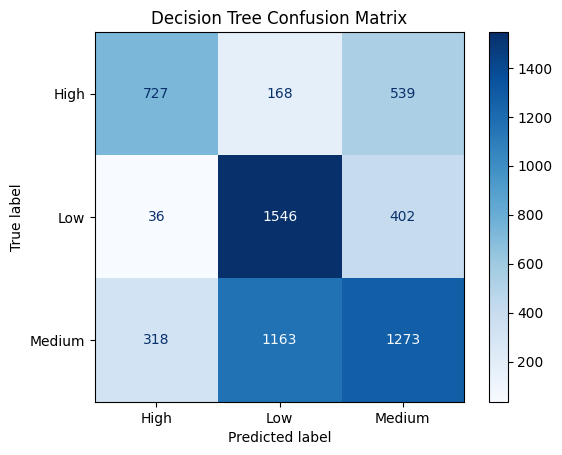

In [9]:
# Confusion matrix as a heatmap
cm = confusion_matrix(y_test, y_pred_test, labels=best_gnb.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.inverse_transform(best_gnb.classes_))
disp.plot(cmap=plt.cm.Blues)
plt.title("Decision Tree Confusion Matrix")
plt.show()


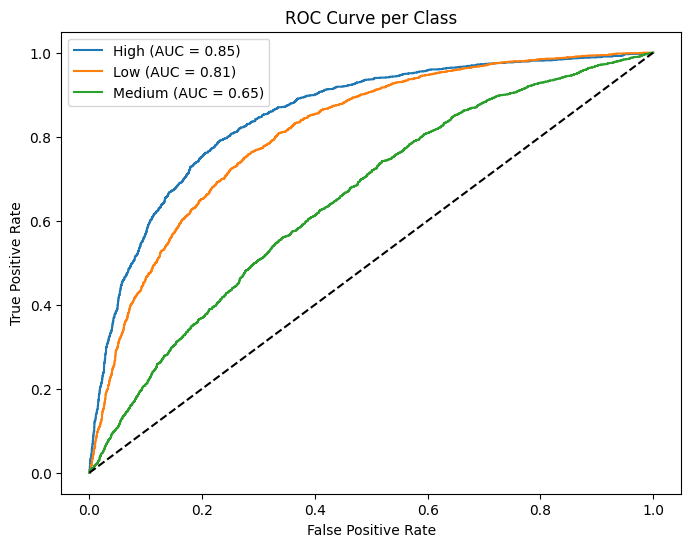

In [10]:
y_bin = label_binarize(y_test, classes=best_gnb.classes_)
y_score = best_gnb.predict_proba(X_test)

plt.figure(figsize=(8,6))
for i, class_label in enumerate(best_gnb.classes_):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f'{le.inverse_transform(best_gnb.classes_)[i]} (AUC = {auc(fpr, tpr):.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve per Class")
plt.legend()
plt.show()


The confusion matrix shows Low is identified best (strong diagonal), while Medium is frequently misclassified as Low and High is often misclassified as Medium. Direct High <-> Low confusion is relatively small compared to the Medium-related errors.